In [1]:
import torch
import torchaudio
print(torchaudio.__version__)

2.11.0+cpu


In [2]:
import os
os.makedirs('./data', exist_ok=True)

dataset = torchaudio.datasets.YESNO(root='./data', download=True)
print(len(dataset))

60


In [3]:
waveform, sr, labels = dataset[0]
print(waveform.shape)
print(sr)
print(labels)

torch.Size([1, 50800])
8000
[0, 0, 0, 0, 1, 1, 1, 1]


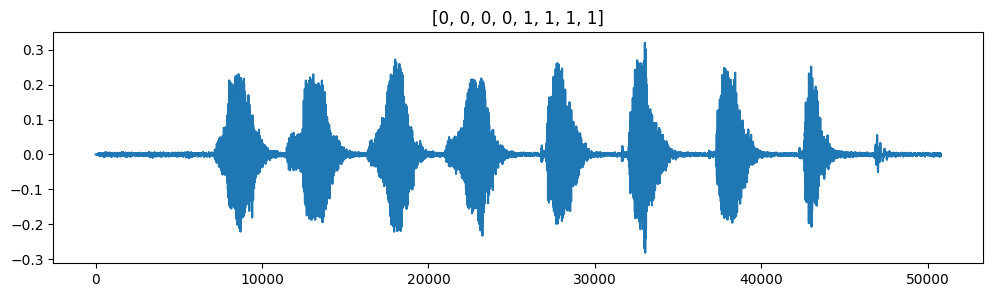

In [4]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 3))
plt.plot(waveform[0])
plt.title(labels)
plt.show()

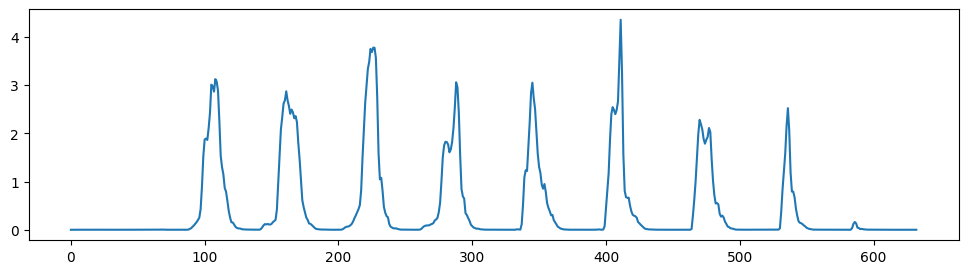

In [5]:
import numpy as np

x = waveform[0].numpy()
frame = 200   # 25 ms
hop = 80      # 10 ms

energy = []
for i in range(0, len(x) - frame, hop):
    energy.append(np.sum(x[i:i+frame] ** 2))
energy = np.array(energy)

plt.figure(figsize=(12, 3))
plt.plot(energy)
plt.show()

Number of words: 8
[(98, 118), (155, 175), (216, 235), (276, 295), (338, 358), (401, 419), (466, 485), (532, 543)]


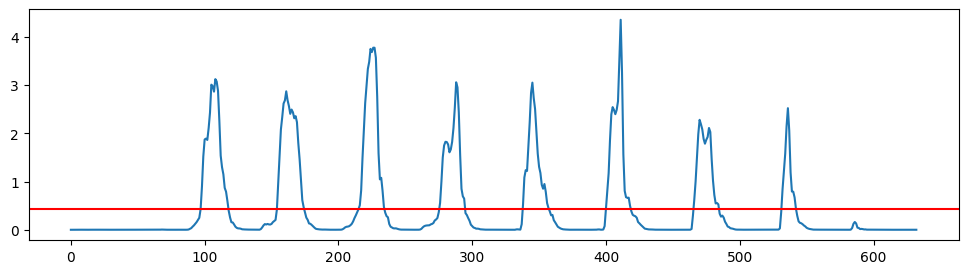

In [6]:
threshold = 0.1 * energy.max()
active = energy > threshold

segments = []
start = None
for i in range(len(active)):
    if active[i] and start is None:
        start = i
    elif not active[i] and start is not None:
        segments.append((start, i))
        start = None

print('Number of words:', len(segments))
print(segments)

plt.figure(figsize=(12, 3))
plt.plot(energy)
plt.axhline(threshold, color='red')
plt.show()

In [7]:
def segment_words(waveform, n_words=8, frame=200, hop=80, min_gap=800, min_len=800):
    x = waveform[0].numpy()
    energy = np.array([np.sum(x[i:i+frame] ** 2) for i in range(0, len(x) - frame, hop)])

    best = None
    for ratio in np.linspace(0.3, 0.01, 60):
        active = energy > ratio * energy.max()

        segments = []
        start = None
        for i in range(len(active)):
            if active[i] and start is None:
                start = i
            elif not active[i] and start is not None:
                segments.append([start * hop, i * hop + frame])
                start = None
        if start is not None:
            segments.append([start * hop, len(x)])

        merged = []
        for s in segments:
            if merged and s[0] - merged[-1][1] < min_gap:
                merged[-1][1] = s[1]
            else:
                merged.append(s)

        merged = [s for s in merged if s[1] - s[0] >= min_len]

        if len(merged) == n_words:
            return merged
        if best is None or abs(len(merged) - n_words) < abs(len(best) - n_words):
            best = merged
    return best


counts = []
for i in range(len(dataset)):
    waveform, sr, labels = dataset[i]
    counts.append(len(segment_words(waveform)))

print(counts)
print('Files with 8 words:', counts.count(8), '/', len(counts))
print('Bad files:', [i for i, c in enumerate(counts) if c != 8])

[8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 7, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8]
Files with 8 words: 59 / 60
Bad files: [21]


In [8]:
words = []
word_labels = []
groups = []

for i in range(len(dataset)):
    waveform, sr, labels = dataset[i]
    segments = segment_words(waveform)
    if len(segments) != 8:
        continue
    for (s, e), label in zip(segments, labels):
        words.append(waveform[:, s:e])
        word_labels.append(label)
        groups.append(i)

word_labels = np.array(word_labels)
groups = np.array(groups)

print('Total words:', len(words))
print('Yes:', word_labels.sum(), '| No:', len(word_labels) - word_labels.sum())
lengths = [w.shape[1] / 8000 for w in words]
print('Word length (s): min %.2f, mean %.2f, max %.2f' % (min(lengths), np.mean(lengths), max(lengths)))

Total words: 472
Yes: 249 | No: 223
Word length (s): min 0.10, mean 0.17, max 0.34


In [9]:
import torchaudio.transforms as T
import torchaudio.functional as AF

mfcc_transform = T.MFCC(sample_rate=8000, n_mfcc=13,
                        melkwargs={'n_fft': 256, 'hop_length': 80, 'n_mels': 40})

def extract_features(word):
    mfcc = mfcc_transform(word)[0]
    delta = AF.compute_deltas(mfcc.unsqueeze(0))[0]
    feats = torch.cat([mfcc, delta], dim=0)
    return torch.cat([feats.mean(dim=1), feats.std(dim=1)]).numpy()

X = np.stack([extract_features(w) for w in words])
y = word_labels

print('X shape:', X.shape)
print('y shape:', y.shape)

X shape: (472, 52)
y shape: (472,)


In [10]:
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, test_idx = next(gss.split(X, y, groups))

X_train, X_test = X[train_idx], X[test_idx]
y_train, y_test = y[train_idx], y[test_idx]

print('Train words:', len(y_train), '| Test words:', len(y_test))
print('Train files:', len(set(groups[train_idx])), '| Test files:', len(set(groups[test_idx])))

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

clf = LogisticRegression(max_iter=1000)
clf.fit(X_train, y_train)
pred = clf.predict(X_test)

print('Logistic Regression accuracy:', accuracy_score(y_test, pred))

Train words: 376 | Test words: 96
Train files: 47 | Test files: 12
Logistic Regression accuracy: 1.0


Number of recordings: 60
Total words: 472 | Yes: 249 | No: 223
X shape: (472, 52) | y shape: (472,)
Train words: 376 | Test words: 96

                     Test Acc  Test F1  CV Acc
Logistic Regression       1.0      1.0   1.000
SVM (RBF)                 1.0      1.0   1.000
KNN (k=5)                 1.0      1.0   1.000
Random Forest             1.0      1.0   1.000
Naive Bayes               1.0      1.0   1.000
MLP                       1.0      1.0   1.000
Decision Tree             1.0      1.0   0.994


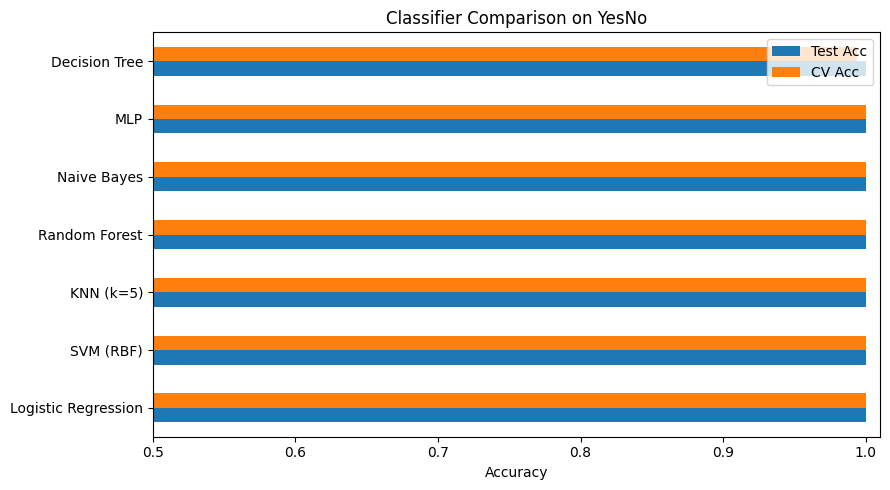

In [11]:
import os
import numpy as np
import torch
import torchaudio
import torchaudio.transforms as T
import torchaudio.functional as AF
import matplotlib.pyplot as plt
import pandas as pd

from sklearn.model_selection import GroupShuffleSplit, GroupKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, f1_score

os.makedirs('./data', exist_ok=True)
dataset = torchaudio.datasets.YESNO(root='./data', download=True)
print('Number of recordings:', len(dataset))


def segment_words(waveform, n_words=8, frame=200, hop=80, min_gap=800, min_len=800):
    x = waveform[0].numpy()
    energy = np.array([np.sum(x[i:i+frame] ** 2) for i in range(0, len(x) - frame, hop)])
    best = None
    for ratio in np.linspace(0.3, 0.01, 60):
        active = energy > ratio * energy.max()
        segments = []
        start = None
        for i in range(len(active)):
            if active[i] and start is None:
                start = i
            elif not active[i] and start is not None:
                segments.append([start * hop, i * hop + frame])
                start = None
        if start is not None:
            segments.append([start * hop, len(x)])
        merged = []
        for s in segments:
            if merged and s[0] - merged[-1][1] < min_gap:
                merged[-1][1] = s[1]
            else:
                merged.append(s)
        merged = [s for s in merged if s[1] - s[0] >= min_len]
        if len(merged) == n_words:
            return merged
        if best is None or abs(len(merged) - n_words) < abs(len(best) - n_words):
            best = merged
    return best


words, word_labels, groups = [], [], []
for i in range(len(dataset)):
    waveform, sr, labels = dataset[i]
    segments = segment_words(waveform)
    if len(segments) != 8:
        continue
    for (s, e), label in zip(segments, labels):
        words.append(waveform[:, s:e])
        word_labels.append(label)
        groups.append(i)
word_labels = np.array(word_labels)
groups = np.array(groups)
print('Total words:', len(words), '| Yes:', word_labels.sum(), '| No:', len(word_labels) - word_labels.sum())


mfcc_transform = T.MFCC(sample_rate=8000, n_mfcc=13,
                        melkwargs={'n_fft': 256, 'hop_length': 80, 'n_mels': 40})

def extract_features(word):
    mfcc = mfcc_transform(word)[0]
    delta = AF.compute_deltas(mfcc.unsqueeze(0))[0]
    feats = torch.cat([mfcc, delta], dim=0)
    return torch.cat([feats.mean(dim=1), feats.std(dim=1)]).numpy()

X = np.stack([extract_features(w) for w in words])
y = word_labels
print('X shape:', X.shape, '| y shape:', y.shape)


gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, test_idx = next(gss.split(X, y, groups))
y_test = y[test_idx]
print('Train words:', len(train_idx), '| Test words:', len(test_idx))


models = {
    'Logistic Regression': LogisticRegression(max_iter=1000),
    'SVM (RBF)': SVC(kernel='rbf'),
    'KNN (k=5)': KNeighborsClassifier(n_neighbors=5),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=200, random_state=42),
    'Naive Bayes': GaussianNB(),
    'MLP': MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=1000, random_state=42),
}

results = {}
for name, model in models.items():
    pipe = make_pipeline(StandardScaler(), model)
    pipe.fit(X[train_idx], y[train_idx])
    pred = pipe.predict(X[test_idx])
    test_acc = accuracy_score(y_test, pred)
    test_f1 = f1_score(y_test, pred)
    cv_acc = cross_val_score(pipe, X, y, groups=groups, cv=GroupKFold(n_splits=5)).mean()
    results[name] = [test_acc, test_f1, cv_acc]

df = pd.DataFrame(results, index=['Test Acc', 'Test F1', 'CV Acc']).T
df = df.sort_values('CV Acc', ascending=False)
print()
print(df.round(3))

df[['Test Acc', 'CV Acc']].plot(kind='barh', figsize=(9, 5), xlim=(0.5, 1.01))
plt.title('Classifier Comparison on YesNo')
plt.xlabel('Accuracy')
plt.tight_layout()
plt.show()

Spectrogram tensor shape: torch.Size([472, 1, 40, 41])


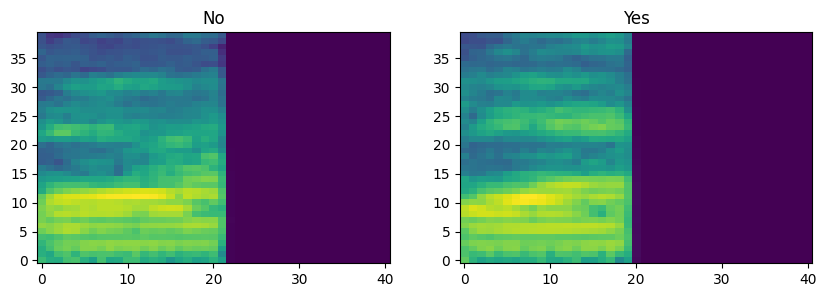

SmallCNN(
  (net): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (10): ReLU()
    (11): AdaptiveAvgPool2d(output_size=1)
    (12): Flatten(start_dim=1, end_dim=-1)
    (13): Dropout(p=0.3, inplace=False)
    (14): Linear(in_features=64, out_features=2, bias=True)
  )
)


In [12]:
import torch.nn as nn

MAX_LEN = 3200
mel_transform = T.MelSpectrogram(sample_rate=8000, n_fft=256, hop_length=80, n_mels=40)

def to_logmel(w):
    w = w[:, :MAX_LEN]
    w = nn.functional.pad(w, (0, MAX_LEN - w.shape[1]))
    return torch.log(mel_transform(w) + 1e-6)

S = torch.stack([to_logmel(w) for w in words])
Y = torch.tensor(y, dtype=torch.long)
print('Spectrogram tensor shape:', S.shape)

fig, ax = plt.subplots(1, 2, figsize=(10, 3))
for k, label in enumerate([0, 1]):
    idx = np.where(y == label)[0][0]
    ax[k].imshow(S[idx, 0], origin='lower', aspect='auto')
    ax[k].set_title('No' if label == 0 else 'Yes')
plt.show()


class SmallCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(1, 16, 3, padding=1), nn.BatchNorm2d(16), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(16, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(), nn.AdaptiveAvgPool2d(1),
            nn.Flatten(), nn.Dropout(0.3), nn.Linear(64, 2)
        )

    def forward(self, x):
        return self.net(x)

print(SmallCNN())

Epoch  5 | loss 0.2468
Epoch 10 | loss 0.0687
Epoch 15 | loss 0.0411
Epoch 20 | loss 0.0254
Epoch 25 | loss 0.0159
Epoch 30 | loss 0.0139

CNN Test acc: 1.0 | F1: 1.0 | CV acc: 0.996

                     Test Acc  Test F1  CV Acc
Logistic Regression       1.0      1.0   1.000
SVM (RBF)                 1.0      1.0   1.000
KNN (k=5)                 1.0      1.0   1.000
Random Forest             1.0      1.0   1.000
Naive Bayes               1.0      1.0   1.000
MLP                       1.0      1.0   1.000
Decision Tree             1.0      1.0   0.994
CNN (Log-Mel)             1.0      1.0   0.996


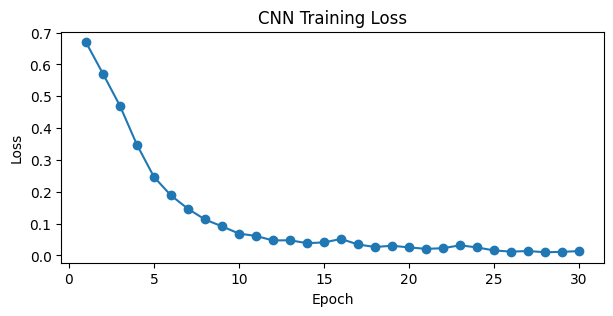

In [13]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'

def train_cnn(tr_idx, te_idx, epochs=30, verbose=False):
    torch.manual_seed(42)
    mean, std = S[tr_idx].mean(), S[tr_idx].std()
    Xtr = (S[tr_idx] - mean) / std
    Xte = (S[te_idx] - mean) / std
    loader = torch.utils.data.DataLoader(
        torch.utils.data.TensorDataset(Xtr, Y[tr_idx]), batch_size=32, shuffle=True)

    model = SmallCNN().to(device)
    opt = torch.optim.Adam(model.parameters(), lr=1e-3)
    loss_fn = nn.CrossEntropyLoss()

    history = []
    for epoch in range(epochs):
        model.train()
        total = 0
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            opt.zero_grad()
            loss = loss_fn(model(xb), yb)
            loss.backward()
            opt.step()
            total += loss.item() * len(yb)
        history.append(total / len(tr_idx))
        if verbose and (epoch + 1) % 5 == 0:
            print(f'Epoch {epoch+1:2d} | loss {history[-1]:.4f}')

    model.eval()
    with torch.no_grad():
        pred = model(Xte.to(device)).argmax(1).cpu().numpy()
    return pred, history


pred, history = train_cnn(train_idx, test_idx, verbose=True)
cnn_test_acc = accuracy_score(y_test, pred)
cnn_test_f1 = f1_score(y_test, pred)

cv_scores = []
for tr, te in GroupKFold(n_splits=5).split(S, y, groups):
    p, _ = train_cnn(tr, te)
    cv_scores.append(accuracy_score(y[te], p))
cnn_cv_acc = np.mean(cv_scores)

print()
print('CNN Test acc:', cnn_test_acc, '| F1:', cnn_test_f1, '| CV acc:', round(cnn_cv_acc, 3))

df.loc['CNN (Log-Mel)'] = [cnn_test_acc, cnn_test_f1, cnn_cv_acc]
print()
print(df.round(3))

plt.figure(figsize=(7, 3))
plt.plot(range(1, 31), history, marker='o')
plt.title('CNN Training Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.show()